# GreenBox AI – Previsão do consumo energético

Notebook de desenvolvimento do modelo de previsão do consumo energético das **24 horas seguintes** (RF13).

Enquanto não existem dados da GreenBox, usa-se o dataset público **Appliances Energy Prediction** (UCI Machine Learning Repository, Candanedo, 2017, licença CC BY 4.0), que tem a mesma estrutura do problema: sensores interiores + meteorologia exterior → consumo.

**Estrutura do notebook**
1. Carregar os dados (a única parte que muda quando se troca de dataset)
2. Preparar os dados (agregação horária e variáveis)
3. Dividir cronologicamente em treino e teste
4. Treinar os modelos: referência, regressão linear e Random Forest
5. Avaliar com MAE e RMSE

> Para trocar para os dados da GreenBox basta mudar a linha `dados = carregar_kaggle()` na secção 1.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Funciona quer o notebook corra a partir da pasta ia/ quer da raiz do projeto
PASTA_DADOS = next((p for p in [Path("dados"), Path("ia/dados")] if p.is_dir()), Path("dados"))
SEMENTE = 42

## 1. Carregar os dados

Cada fonte de dados tem a sua função de carregamento. Todas devolvem um `DataFrame` com **as mesmas colunas padrão**:

| Coluna | Significado |
|---|---|
| `data_hora` | Data e hora da medição |
| `consumo_wh` | Consumo energético no intervalo (Wh) |
| `temp_interior` | Temperatura interior (°C) |
| `humidade_interior` | Humidade relativa interior (%) |
| `temp_exterior` | Temperatura exterior (°C) – fonte externa |
| `humidade_exterior` | Humidade relativa exterior (%) – fonte externa |

**Dataset:** o ficheiro `ia/dados/energydata_complete.csv` (UCI, CC BY 4.0) já está no repositório. Citação: Candanedo, L. (2017). *Appliances Energy Prediction* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5VC8G

In [2]:
def carregar_kaggle(pasta=PASTA_DADOS):
    """Appliances Energy Prediction: leituras a cada 10 minutos de uma casa de baixo consumo."""
    # Usa primeiro a versão da UCI incluída no repositório; aceita também a cópia do Kaggle
    candidatos = sorted(pasta.glob("*.csv"), key=lambda f: f.name != "energydata_complete.csv")
    ficheiros = [f for f in candidatos
                 if {"date", "Appliances"} <= set(pd.read_csv(f, nrows=0).columns)]
    if not ficheiros:
        raise FileNotFoundError(f"Não foi encontrado o CSV do Appliances Energy Prediction em {pasta.resolve()}")
    df = pd.read_csv(ficheiros[0], parse_dates=["date"])

    # T6/RH_6 são medidos no exterior do edifício, por isso ficam fora da média interior
    colunas_temp = [f"T{i}" for i in range(1, 10) if i != 6]
    colunas_hum = [f"RH_{i}" for i in range(1, 10) if i != 6]

    return pd.DataFrame({
        "data_hora": df["date"],
        "consumo_wh": df["Appliances"] + df["lights"],
        "temp_interior": df[colunas_temp].mean(axis=1),
        "humidade_interior": df[colunas_hum].mean(axis=1),
        "temp_exterior": df["T_out"],
        "humidade_exterior": df["RH_out"],
    })


def carregar_greenbox():
    """A implementar quando existirem dados da GreenBox (BD do servidor local ou CSV exportado)
    juntos com a meteorologia da Open-Meteo. Deve devolver as mesmas colunas padrão."""
    raise NotImplementedError("Ainda não existem dados da GreenBox.")

In [3]:
dados = carregar_kaggle()
print(dados.shape)
dados.head()

(19735, 6)


,data_hora,consumo_wh,temp_interior,humidade_interior,temp_exterior,humidade_exterior
0,2016-01-11 17:00:00,90,18.435000,46.742500,6.600000,92.0
1,2016-01-11 17:10:00,90,18.439167,46.672708,6.483333,92.0
2,2016-01-11 17:20:00,80,18.421667,46.562917,6.366667,92.0
3,2016-01-11 17:30:00,90,18.396250,46.468750,6.250000,92.0
4,2016-01-11 17:40:00,100,18.408750,46.462917,6.133333,92.0


## 2. Preparar os dados

- **Agregação horária:** o consumo é somado em cada hora; as restantes variáveis usam a média.
- **Valores em falta:** horas sem leituras são preenchidas por interpolação.
- **Variáveis do modelo:** só se usa informação que existe **no momento da previsão**, porque o RF13 prevê as 24 horas seguintes:
  - hora do dia, dia da semana e fim de semana;
  - consumo à mesma hora do dia anterior (`consumo_lag_24`);
  - consumo médio das 24 horas anteriores ao dia anterior;
  - temperatura e humidade exteriores, que no sistema real vêm da **previsão meteorológica** da Open-Meteo.

As variáveis interiores não entram como entrada do modelo, porque não se conhecem com 24 horas de antecedência.

In [4]:
def agregar_por_hora(df):
    horario = (df.set_index("data_hora")
                 .resample("1h")
                 .agg({"consumo_wh": "sum", "temp_interior": "mean", "humidade_interior": "mean",
                       "temp_exterior": "mean", "humidade_exterior": "mean"}))
    return horario.interpolate(limit_direction="both")


def criar_variaveis(horario):
    df = horario.copy()
    df["hora"] = df.index.hour
    df["dia_semana"] = df.index.dayofweek
    df["fim_de_semana"] = (df["dia_semana"] >= 5).astype(int)
    df["consumo_lag_24"] = df["consumo_wh"].shift(24)
    df["consumo_media_24h"] = df["consumo_wh"].shift(24).rolling(24).mean()
    return df.dropna()


VARIAVEIS = ["hora", "dia_semana", "fim_de_semana", "consumo_lag_24",
             "consumo_media_24h", "temp_exterior", "humidade_exterior"]
ALVO = "consumo_wh"

horario = criar_variaveis(agregar_por_hora(dados))
print(f"{len(horario)} horas, de {horario.index.min()} a {horario.index.max()}")
horario[VARIAVEIS + [ALVO]].describe().round(1)

3243 horas, de 2016-01-13 16:00:00 a 2016-05-27 18:00:00


C:\Users\claud\AppData\Local\Temp\ipykernel_22752\1319096259.py:12: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df["dia_semana"] = df.index.dayofweek


,hora,dia_semana,fim_de_semana,consumo_lag_24,consumo_media_24h,temp_exterior,humidade_exterior,consumo_wh
count,3243.0,3243.0,3243.0,3243.0,3243.0,3243.0,3243.0,3243.0
mean,11.5,3.0,0.3,606.9,605.2,7.4,79.6,609.3
std,6.9,2.0,0.4,498.8,179.3,5.3,14.9,499.4
min,0.0,0.0,0.0,170.0,221.2,-5.0,25.2,170.0
25%,6.0,1.0,0.0,310.0,481.9,3.6,70.2,310.0
50%,12.0,3.0,0.0,400.0,574.6,7.0,83.6,400.0
75%,17.5,5.0,1.0,700.0,692.7,10.5,91.6,710.0
max,23.0,6.0,1.0,3740.0,1230.4,25.9,100.0,3740.0


## 3. Divisão cronológica em treino e teste

Os primeiros 80 % do período servem para treino e os últimos 20 % para teste. Não se baralham os dados: o teste é sempre **posterior** ao treino, como exige o critério do RF13.

In [5]:
corte = int(len(horario) * 0.8)
treino, teste = horario.iloc[:corte], horario.iloc[corte:]
print(f"Treino: {treino.index.min()} até {treino.index.max()} ({len(treino)} h)")
print(f"Teste:  {teste.index.min()} até {teste.index.max()} ({len(teste)} h)")

Treino: 2016-01-13 16:00:00 até 2016-04-30 17:00:00 (2594 h)
Teste:  2016-04-30 18:00:00 até 2016-05-27 18:00:00 (649 h)


## 4. Modelos

- **Modelo de referência:** média do consumo por hora do dia, calculada no treino. É o valor a bater (glossário do relatório de requisitos).
- **Regressão linear**
- **Random Forest**

In [6]:
media_por_hora = treino.groupby("hora")[ALVO].mean()
previsoes = {"Referência (média por hora)": teste["hora"].map(media_por_hora).to_numpy()}

modelos = {
    "Regressão linear": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                                           random_state=SEMENTE, n_jobs=-1),
}
for nome, modelo in modelos.items():
    modelo.fit(treino[VARIAVEIS], treino[ALVO])
    previsoes[nome] = modelo.predict(teste[VARIAVEIS])

## 5. Avaliação

O critério do RF13 é o **MAE** (erro absoluto médio, em Wh por hora): o modelo tem de ter um MAE inferior ao do modelo de referência.

In [7]:
mae_ref = mean_absolute_error(teste[ALVO], previsoes["Referência (média por hora)"])
resultados = pd.DataFrame([
    {"Modelo": nome,
     "MAE (Wh)": mean_absolute_error(teste[ALVO], prev),
     "RMSE (Wh)": mean_squared_error(teste[ALVO], prev) ** 0.5,
     "Melhoria face à referência": 1 - mean_absolute_error(teste[ALVO], prev) / mae_ref}
    for nome, prev in previsoes.items()
]).set_index("Modelo")
resultados.style.format({"MAE (Wh)": "{:.1f}", "RMSE (Wh)": "{:.1f}", "Melhoria face à referência": "{:.1%}"})

,MAE (Wh),RMSE (Wh),Melhoria face à referência
Modelo,,,
Referência (média por hora),244.9,367.5,0.0%
Regressão linear,276.3,383.4,-12.8%
Random Forest,229.7,356.2,6.2%


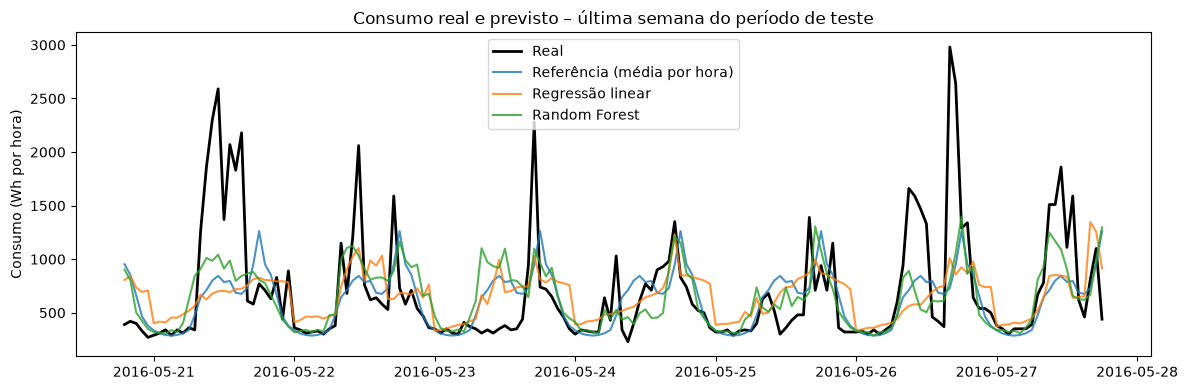

In [8]:
ultima_semana = teste.index[-24 * 7:]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(ultima_semana, teste.loc[ultima_semana, ALVO], label="Real", color="black", linewidth=2)
for nome, prev in previsoes.items():
    ax.plot(ultima_semana, pd.Series(prev, index=teste.index).loc[ultima_semana], label=nome, alpha=0.8)
ax.set_title("Consumo real e previsto – última semana do período de teste")
ax.set_ylabel("Consumo (Wh por hora)")
ax.legend()
plt.tight_layout()
plt.show()

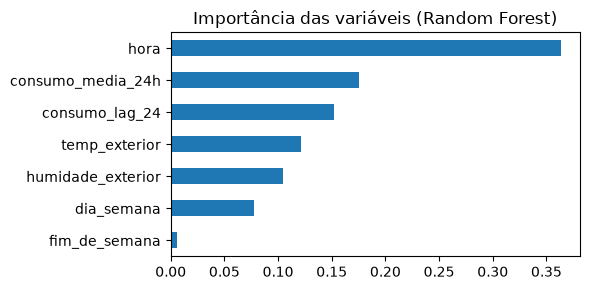

In [9]:
importancia = pd.Series(modelos["Random Forest"].feature_importances_, index=VARIAVEIS).sort_values()
importancia.plot.barh(figsize=(6, 3), title="Importância das variáveis (Random Forest)")
plt.tight_layout()
plt.show()

## Próximos passos

- Implementar `carregar_greenbox()` quando existirem dados da estufa, juntando a meteorologia da Open-Meteo.
- Ajustar as variáveis à estufa (zonas e consumo por equipamento: iluminação, ventilação, bomba).
- Registar os resultados para o planeamento do modelo (entrega de IA a 18/12).